# 03 · Forward mode: where does the water in each cell come from?

Tutorial 01 traced *backward* from a well: for every cell, what share of its water ends up in the well. This tutorial turns the question around and traces *forward* from sources: for every cell, what share of its water **came from** the stream, from regional inflow across the west edge, or from recharge on a particular field. That is the question behind bank filtration ("how much of the pumped water is stream water?"), and behind any diffuse-pollution question ("if this field leaches nitrate, how much reaches the well, and how diluted?").

On the quickstart model of tutorial 01 you will:

1. trace forward from three sources (stream, west edge, recharge) and map the **source fraction** $G$ in every cell;
2. read the well's water by source straight from $G$;
3. use $G$ as a **dilution ratio** $C/C_0$, and mix the sources' concentrations into a concentration map;
4. split each source's water by where it leaves the model: the **volume to** each sink;
5. trace a **recharge zone**, a hypothetical fertilised field, to the well;
6. check **forward/backward duality**: the flow from a source to a destination comes out the same whichever direction computes it;
7. compare $G$ with an MF6 transport model (GWT) run to equilibrium on the same flows.

**Runtime:** about 1 second (the last code cell prints the measured time). **Prerequisites:** tutorials 01 and 02.

## Settings

All settings live in this first cell. The model workspace goes to `tutorials/_work/03_forward/` (git-ignored, recreated on every run). The concentrations are invented for illustration; they are not data.

In [1]:
import sys
import time
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
import herebedragons as hbd  # noqa: E402

import gwsource as gs  # noqa: E402

WORK = hbd.work_dir("03_forward", clean=True)  # tutorials/_work/03_forward (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
WELL = "supply_well"  # boundnames of the well
SOURCES = {"stream": "SFR", "west edge": "CHD", "recharge": "RCH"}  # source group: package
FIELD_ROWS = (10, 16)  # 0-based rows [start, stop) of a hypothetical fertilised field
FIELD_COLS = (12, 18)  # 0-based columns [start, stop) of the field
CONCENTRATION = {"stream": 80.0, "west edge": 25.0, "recharge": 5.0}  # chloride in each source (mg/L)
FIELD_NITRATE = 50.0  # nitrate in the water recharging beneath the field (mg/L)
STREAM_ZOOM = {"xlim": (1100.0, 1700.0), "ylim": (700.0, 1300.0)}  # map window near the well (m)
GWT_PERIOD = (1.0e6, 10, 1.0)  # GWT check: (days, steps, multiplier), long enough for equilibrium
GWT_POROSITY = 0.3  # porosity of the GWT check (-); it sets the speed, not the equilibrium

START = time.perf_counter()  # for the runtime printed in the last code cell

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.0, 5.5)})
print(f"gwsource {gs.__version__}, FloPy {flopy.__version__}")

gwsource 0.0.1, FloPy 3.12.0.dev0


## 1. The model

The same model as tutorial 01: one unconfined layer, 2 km × 2 km in 50 m cells, recharge of 0.5 mm/d everywhere, a constant head on the west edge (regional inflow), a stream (SFR) flowing north to south down column 31 with its stage close to 6 m, and a supply well pumping 800 m³/d at row 21, column 29, 100 m west of the stream. Each stream reach is a source or sink term of its aquifer cell. Rows and columns in the text are counted from 1, from the north-west corner.

In [2]:
run = hbd.build_quickstart(WORK / "model", MF6)
spec = run.spec
step = gs.read_step(run.ws, boundnames=True)
well = gs.select(step, boundnames=[WELL])
well_cell = int(np.flatnonzero(well.cells)[0])
row, col = divmod(well_cell, spec.ncol)  # 0-based
print(f"grid {step.grid_type} {step.grid_shape}; well in row {row + 1}, column {col + 1} (node {well_cell})")
print(f"stream in column {spec.stream_col + 1}")

grid DIS (1, 40, 40); well in row 21, column 29 (node 828)
stream in column 31


## 2. Forward tracing: the source fraction

Forward mode is backward mode run on the reversed graph. Each cell is still fully mixed (tutorial 02), but now we follow the water *upstream*: the water in cell $i$ is a blend of what flows in from its neighbours $j$ and what enters from external sources, in proportion to those inflows. Let $I_i$ be the total inflow of cell $i$ (from neighbours and from all source terms), $q_{ji}$ the flow from neighbour $j$ into $i$, and $b_i$ the inflow from the sources of group $S$. The fraction of the cell's water that came from $S$ is

$$
G_i \;=\; \sum_j \frac{q_{ji}}{I_i}\,G_j \;+\; \frac{b_i}{I_i}
\qquad\Longleftrightarrow\qquad
(\mathbf I-\mathbf Q)\,\mathbf G = \mathbf R\,\mathbf T,
\qquad Q_{ij} = \frac{q_{ji}}{I_i},
$$

the forward twin of the backward equation, normalised by inflow instead of outflow.

**$G$ is a dilution ratio.** Give the water entering through the sources of $S$ a conservative solute at concentration $C_0$, and all other inflow none. At steady state, with full mixing, each cell's concentration is $C_i = G_i\,C_0$. $G$ is exactly what an MF6 transport model (GWT) with upstream advection and no dispersion converges to after a long enough time with unit concentration on those sources (section 9 makes that comparison).

What $G$ does *not* say:

- **when** the water arrives: $G$ is the long-term, equilibrium value. Travel times are in tutorials 06 and 08;
- anything about **reactions**: sorption, decay or denitrification would lower $C$ below $G\,C_0$;
- the **sharpness** of a plume: full mixing smears its edges over a few cells, as it smears capture-zone edges (tutorial 01).

Define one source group per inflow package and trace forward. Selections pick terms exactly as in backward mode; in forward mode only selected terms that bring water *in* act as sources.

solver: topological
    stream:   111.7 m3/d enters the model
 west edge:   338.0 m3/d enters the model
  recharge:  1950.0 m3/d enters the model


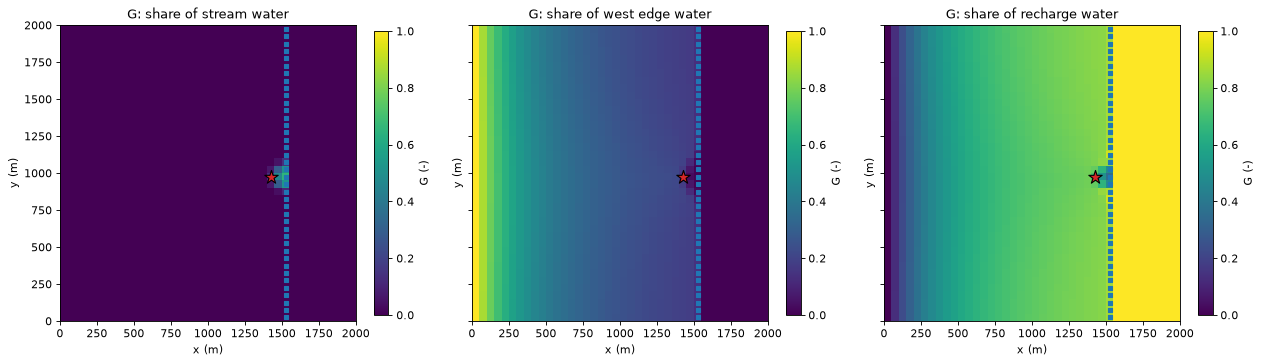

In [3]:
sources = {name: gs.select(step, package=package) for name, package in SOURCES.items()}
fwd = gs.forward(step, sources)
print("solver:", fwd.solver_used[0])
for name in sources:
    print(f"{name:>10}: {fwd.source_inflow[name]:7.1f} m3/d enters the model")

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.6), sharey=True)
for ax, name in zip(axes, sources):
    hbd.plot_cells(
        run.grb_file, step, fwd.source_fraction[name], ax=ax, cmap="viridis", vmin=0.0, vmax=1.0,
        overlay=False, label="G (-)", title=f"G: share of {name} water",
    )
    hbd.overlay_features(ax, run.grb_file, step, packages=("SFR", "WEL"), legend=False)
fig.tight_layout()
plt.show()

**How to read the maps.** Each map shows, cell by cell, the share of the water that entered the model through one source.

- **West edge:** the regional inflow fills the cells along the west edge ($G \approx 1$) and is diluted eastwards as recharge is added on top, cell after cell.
- **Recharge:** the mirror image. Far from the west edge most of the water is recharge, and east of the stream all of it is: the stream drains the regional inflow before it gets there. Away from the well, the two maps add up to 1: there is no other source.
- **Stream:** stream water appears only near the well, where pumping draws the water table below the stream stage and the stream reaches lose water to the aquifer. The pumping draws that water to the well; it does not travel far.

Every cell's water must have come from *some* source, so with one group per source package the fractions add up to 1 in every cell with inflow, the forward twin of the boundary-control maps of tutorial 02:

In [4]:
inflow_cells = gs.cell_budget(step).inflow > 0.0
total_g = sum(fwd.source_fraction[name] for name in sources)
print(f"sum of G over the sources: min {total_g[inflow_cells].min():.15f}, max {total_g[inflow_cells].max():.15f}")
assert np.allclose(total_g[inflow_cells], 1.0, rtol=0.0, atol=1e-12)

sum of G over the sources: min 1.000000000000000, max 1.000000000000000


## 3. The well's water by source

The well removes the water of its own cell, so the source fractions **in the well cell** are the shares of the pumped water by source. One forward trace answers "what fraction of the well's water is stream water?" directly:

In [5]:
at_well = pd.DataFrame(
    {
        "share of the pumped water (G)": {name: fwd.source_fraction[name][well_cell] for name in sources},
        "volume (m3/d)": {name: fwd.volume_to_by_term[name]["WEL"].sum() for name in sources},
    }
)
display(at_well.round(3))
print(f"total: {at_well['share of the pumped water (G)'].sum():.6f} of the water, "
      f"{at_well['volume (m3/d)'].sum():.2f} m3/d")

,share of the pumped water (G),volume (m3/d)
stream,0.140,111.672
west edge,0.153,122.425
recharge,0.707,565.903


total: 1.000000 of the water, 800.00 m3/d


About 14 % of the pumped water is stream water, 15 % regional inflow and 71 % recharge: the same split as the backward trace of tutorial 01 (volume from by source), reached from the other direction. Section 7 shows why the two must agree.

## 4. Source fraction as a dilution ratio

Suppose the stream carries a conservative solute, say chloride at 80 mg/L from a treated-wastewater outfall upstream. With no other chloride in the system, the steady-state concentration in each cell is $C_i = G_i \times 80$ mg/L, and in the well about 0.14 × 80 ≈ 11 mg/L. The left map below shows $G_\text{stream} = C/C_0$ near the well, with contours.

When every source carries the solute at its own concentration $C_g$, the concentrations simply mix by the source fractions, because full mixing is linear:

$$
C_i = \sum_g G_{ig}\,C_g ,
$$

a flow-weighted mixing of end-members. With the invented values of the settings cell (stream 80, regional groundwater 25, recharge 5 mg/L), the right map shows the resulting chloride concentration.

chloride by source (mg/L): {'stream': 80.0, 'west edge': 25.0, 'recharge': 5.0}
chloride in the well: 18.5 mg/L (stream alone: 11.2 mg/L)
losing stream reaches in rows 19 to 23; G in the stream cells at most 0.65
chloride (mg/L): 25.0 at the west edge, 8.4 to 8.8 just west of the stream, 5.0 east of it, at most 53.8


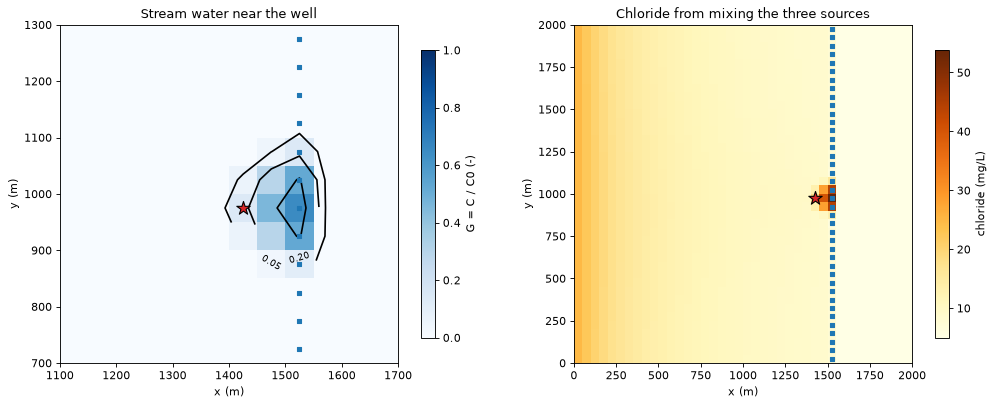

In [6]:
chloride = sum(fwd.source_fraction[name] * CONCENTRATION[name] for name in sources)
print("chloride by source (mg/L):", CONCENTRATION)
print(f"chloride in the well: {chloride[well_cell]:.1f} mg/L "
      f"(stream alone: {fwd.source_fraction['stream'][well_cell] * CONCENTRATION['stream']:.1f} mg/L)")
sfr_terms = step.term_package == step.package_names.index("SFR")
losing_rows = step.term_cell[sfr_terms & (step.term_flow > 0.0)] // spec.ncol + 1  # 1-based
print(f"losing stream reaches in rows {losing_rows.min()} to {losing_rows.max()}; "
      f"G in the stream cells at most {fwd.source_fraction['stream'][step.term_cell[sfr_terms]].max():.2f}")
cl_grid = chloride.reshape(spec.nrow, spec.ncol)
west_of_stream = np.delete(cl_grid[:, spec.stream_col - 1], losing_rows - 1)  # away from the losing reaches
print(f"chloride (mg/L): {cl_grid[:, 0].min():.1f} at the west edge, {west_of_stream.min():.1f} to "
      f"{west_of_stream.max():.1f} just west of the stream, {cl_grid[:, spec.stream_col + 1:].max():.1f} east of it, "
      f"at most {chloride.max():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.0))
g_stream = fwd.source_fraction["stream"]
hbd.plot_cells(
    run.grb_file, step, g_stream, ax=axes[0], cmap="Blues", vmin=0.0, vmax=1.0, overlay=False,
    label="G = C / C0 (-)", title="Stream water near the well",
)
hbd.add_contours(axes[0], run.grb_file, step, g_stream, (0.05, 0.2, 0.5), colors="k", fmt="%.2f")
axes[0].set(**STREAM_ZOOM)
hbd.plot_cells(
    run.grb_file, step, chloride, ax=axes[1], cmap="YlOrBr", overlay=False, label="chloride (mg/L)",
    title="Chloride from mixing the three sources",
)
for ax in axes:
    hbd.overlay_features(ax, run.grb_file, step, packages=("SFR", "WEL"), legend=False)
fig.tight_layout()
plt.show()

Stream water reaches only a few cells: the losing reaches (rows 19 to 23) and the cells between them and the well. In the stream cells themselves $G$ is at most 0.65, because they also receive groundwater from their neighbours, which mixes with the leakage. On the right, chloride falls from 25 mg/L at the west edge (regional groundwater) to about 8.5 mg/L just west of the stream, as recharge (5 mg/L) dilutes it. East of the stream it is 5 mg/L, because all the water there is recharge. Around the losing reaches it rises, up to 53.8 mg/L in the stream cell that leaks most. The well pumps a blend of 18.5 mg/L.

**Pitfall: full mixing in a sink cell.** In a stream cell that *gains* water, the water leaving through the streambed has the cell's mixed concentration. The method cannot separate water that passes under the stream from water that leaves through it; a finer grid or more layers can (tutorial 02, weak sinks).

## 5. Volume to: where does each source's water leave?

**Volume to**, $G_i\,q_{i,k}$ for each sink term $k$ of cell $i$, is the volume rate of the group's water leaving through that sink. `volume_to_by_term` splits it by the package of the sink, so a forward trace gives each source's fate. Summed over all sinks, it equals the water the source brings in (up to the model's budget residual; section 8).

,to the well,to the stream,source inflow,share to the well
stream,111.7,0.0,111.7,1.000
west edge,122.4,215.6,338.0,0.362
recharge,565.9,1384.1,1950.0,0.290


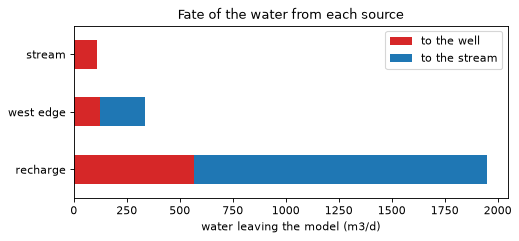

In [7]:
fate = pd.DataFrame(
    {name: {sink: v.sum() for sink, v in fwd.volume_to_by_term[name].items()} for name in sources}
).T
fate.columns = [{"WEL": "to the well", "SFR": "to the stream"}.get(c, c) for c in fate.columns]
fate["source inflow"] = pd.Series(fwd.source_inflow)
fate["share to the well"] = fate["to the well"] / fate["source inflow"]
display(fate.round({"to the well": 1, "to the stream": 1, "source inflow": 1, "share to the well": 3}))

ax = fate[["to the well", "to the stream"]].plot.barh(
    stacked=True, color=["tab:red", "tab:blue"], figsize=(7.0, 2.8)
)
ax.invert_yaxis()
ax.set_xlabel("water leaving the model (m3/d)")
ax.set_title("Fate of the water from each source")
plt.show()

All the stream water that leaks into the aquifer ends up in the well: the losing reaches lie inside the well's capture zone. Of the regional inflow, about a third reaches the well and two thirds drain to the stream; of the 1950 m³/d of recharge, less than a third is pumped. The table reads two ways: by row, the fate of each source; down the "to the well" column, the composition of the pumped water (section 3).

## 6. A recharge zone: a hypothetical fertilised field

A source group does not have to be a whole package. Here a zone array marks a 300 m × 300 m field upgradient of the well, and `gs.select_zone(..., package="RCH")` picks only the **recharge** that falls on it. Suppose the water recharging beneath the field carries 50 mg/L of nitrate. Where does it go, and what concentration reaches the well?

field: 36 recharge cells, 45.0 m3/d of recharge
  to the well:   18.9 m3/d (42%)
  to the stream:  26.1 m3/d (58%)
share of the well's water from the field: G = 0.0236
nitrate in the well: 1.18 mg/L (field leachate 50 mg/L)
G at the field's east edge (column 18): up to 0.25


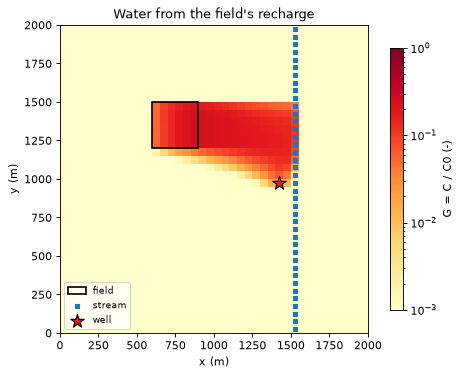

In [8]:
zones = np.zeros((spec.nrow, spec.ncol), dtype=int)
zones[slice(*FIELD_ROWS), slice(*FIELD_COLS)] = 1
field = gs.select_zone(step, zones, 1, package="RCH")
field_fwd = gs.forward(step, {"field": field})
g_field = field_fwd.source_fraction["field"]
field_recharge = field_fwd.source_inflow["field"]
to_well = field_fwd.volume_to_by_term["field"]["WEL"].sum()
to_stream = field_fwd.volume_to_by_term["field"]["SFR"].sum()

print(f"field: {field.terms.sum()} recharge cells, {field_recharge:.1f} m3/d of recharge")
print(f"  to the well:  {to_well:5.1f} m3/d ({to_well / field_recharge:.0%})")
print(f"  to the stream: {to_stream:5.1f} m3/d ({to_stream / field_recharge:.0%})")
print(f"share of the well's water from the field: G = {g_field[well_cell]:.4f}")
print(f"nitrate in the well: {g_field[well_cell] * FIELD_NITRATE:.2f} mg/L "
      f"(field leachate {FIELD_NITRATE:.0f} mg/L)")
east_edge = g_field.reshape(spec.nrow, spec.ncol)[slice(*FIELD_ROWS), FIELD_COLS[1] - 1]
print(f"G at the field's east edge (column {FIELD_COLS[1]}): up to {east_edge.max():.2f}")

ax = hbd.plot_cells(
    run.grb_file, step, np.maximum(g_field, 1e-4), cmap="YlOrRd", norm=LogNorm(1e-3, 1.0),
    overlay=False, label="G = C / C0 (-)", title="Water from the field's recharge",
)
x0, y0 = FIELD_COLS[0] * spec.delr, spec.ly - FIELD_ROWS[1] * spec.delc
size = ((FIELD_COLS[1] - FIELD_COLS[0]) * spec.delr, (FIELD_ROWS[1] - FIELD_ROWS[0]) * spec.delc)
ax.add_patch(Rectangle((x0, y0), *size, fill=False, edgecolor="k", linewidth=1.5, label="field"))
hbd.overlay_features(ax, run.grb_file, step, packages=("SFR", "WEL"), legend=False)
ax.legend(loc="lower left", fontsize=8)
plt.show()

The colour scale is logarithmic; cells below 0.001 (most of the model) take the lightest colour.

- **The plume.** Within the field $G$ grows downgradient as each cell adds its recharge, up to 0.25 at the east edge of the field: even there, three quarters of the water is regional inflow and recharge that fell upgradient. Beyond the field, clean recharge dilutes it further on the way east.
- **The split.** The field straddles the northern edge of the well's capture zone (tutorial 01): its southern rows drain to the well, its northern rows to the stream. The plume divides accordingly, and about 40 % of the field's recharge reaches the well.
- **At the well.** Those 19 m³/d make up 2 % of the 800 m³/d pumped, so 50 mg/L of leachate arrives as about 1 mg/L (at equilibrium, and only if nitrate behaves conservatively).

## 7. Forward/backward duality

The flow from a source group $S$ to a destination $D$ can be computed in either direction (tutorial 02, §4.3):

$$
\underbrace{\sum_{k \in S} F_{c(k)}\, q_k}_{\text{backward from } D}
\;-\;
\underbrace{\sum_{k \in D} G_{c(k)}\, |q_k|}_{\text{forward from } S}
\;=\; \sum_i F_i\, G_i\, r_i ,
$$

where $c(k)$ is the cell of term $k$ and $r_i$ the cell budget residual. The right-hand side is tiny for a converged model. Backward, the sources are weighted by the fraction through $F$ of their cells; forward, the destination's sinks are weighted by the source fraction $G$ of theirs. Below, one backward trace from the well and the forward traces from each source give the flow from each source to the well both ways:

In [9]:
back = gs.backward(step, {"well": well})
fwd_all = gs.forward(step, {**sources, "field": field})
rows = {}
for name in fwd_all.groups:
    check = gs.diagnostics.duality(step, back, "well", fwd_all, name)
    rows[name] = {
        "backward: sum F q (m3/d)": check.lhs,
        "forward: sum G |q| (m3/d)": check.rhs,
        "difference": check.error_without_residual,
        "residual term sum F G r": check.residual_term,
    }
    assert check.relative_error < 1e-10
display(pd.DataFrame(rows).T.map(lambda v: f"{v:.6g}"))

,backward: sum F q (m3/d),forward: sum G |q| (m3/d),difference,residual term sum F G r
stream,111.672,111.672,-7.15374e-11,-7.15295e-11
west edge,122.425,122.425,-1.27838e-07,-1.27838e-07
recharge,565.903,565.903,-2.72928e-07,-2.72928e-07
field,18.9109,18.9109,-8.26372e-09,-8.26372e-09


The two directions agree to better than $10^{-6}$ m³/d, and the difference is exactly the residual term. This is useful in practice, because the two directions scale differently:

- **one backward trace** from a destination gives the flow from *every possible source* to it: every recharge cell, stream reach or zone, chosen after the fact by summing $F\,q$ over the terms of interest;
- **one forward trace** from a source gives its flow to *every sink*, and its concentration everywhere.

So "which of 200 candidate fields contribute most to this well?" is one backward trace, and "which of 30 wells does this field affect, and at what concentration?" is one forward trace. Both directions take many groups in one solve as well.

For the field, the backward trace alone gives the answer: the well's fraction through, weighted by each field cell's recharge.

In [10]:
F_well = back.fraction_through["well"]
field_terms = field.terms
via_backward = float(F_well[step.term_cell[field_terms]] @ step.term_flow[field_terms])
print(f"field recharge reaching the well, backward: {via_backward:.4f} m3/d; forward: {to_well:.4f} m3/d")

field recharge reaching the well, backward: 18.9109 m3/d; forward: 18.9109 m3/d


## 8. Sanity check: each source's water leaves somewhere

Summed over every sink, the volume to equals the water the source brings in, up to the residual term (the forward twin of tutorial 01's closure check):

$$
\sum_i G_i\,\mathrm{Snk}_i \;+\; \sum_i G_i\, r_i \;=\; \sum_{k \in S} q_k .
$$

In [11]:
rows = {}
for name in fwd_all.groups:
    check = gs.diagnostics.forward_closure(step, fwd_all, name)
    rows[name] = {"sum of volume to": check.lhs, "source inflow": check.rhs,
                  "residual term": check.residual_term, "relative error": check.relative_error}
    assert check.relative_error < 1e-10
display(pd.DataFrame(rows).T.map(lambda v: f"{v:.6g}"))

,sum of volume to,source inflow,residual term,relative error
stream,111.672,111.672,7.15295e-11,1.27255e-16
west edge,338.006,338.006,3.6594e-07,1.68173e-16
recharge,1950,1950,9.6586e-07,1.16602e-16
field,45,45,1.85078e-08,1.57898e-16


## 9. An independent check: MF6 transport

Closure and duality follow from the trace equations themselves. They check the computation and the model budget. They do not check the claim of section 2 that $G$ is the concentration a transport model reaches at equilibrium. An MF6 groundwater transport model (GWT) can check it, because it solves the transport equation with its own code.

`hbd.run_gwt_tracer` builds a GWT model that reads the flow model's heads and budget file. Stream leakage enters at a concentration of 1 and all other inflow at 0. Without an SFT package, GWT treats the SFR reaches as plain sources and sinks of their cells, as the trace does. Advection is upstream-weighted and there is no dispersion, the transport model that full mixing corresponds to. The flow model is steady, so MF6 reuses its single budget step for every transport step. The transport model runs for 10⁶ days in 10 steps, long enough for the concentrations to stop changing. Porosity sets how fast the stream water spreads, not where it ends up, so it does not change the equilibrium.

In [12]:
ucn = hbd.run_gwt_tracer(run, WORK / "gwt", MF6, GWT_POROSITY, tagged=("sfr",), perioddata=[GWT_PERIOD])
conc = flopy.utils.HeadFile(str(ucn), text="CONCENTRATION").get_alldata()
conc = conc.reshape(conc.shape[0], -1)  # (time step, cell)
c_gwt = conc[-1]
g_stream = fwd.source_fraction["stream"]
print(f"GWT: {GWT_PERIOD[0]:.0e} days in {conc.shape[0]} steps; largest change over the last step: "
      f"{np.abs(conc[-1] - conc[-2]).max():.1e}")
print(f"largest |G - C| over all {step.n_cells} cells: {np.abs(g_stream - c_gwt).max():.1e}")
print(f"well cell: G = {g_stream[well_cell]:.6f}, C = {c_gwt[well_cell]:.6f}")

GWT: 1e+06 days in 10 steps; largest change over the last step: 5.6e-17
largest |G - C| over all 1600 cells: 3.5e-13
well cell: G = 0.139590, C = 0.139590


The equilibrium concentration of the transport model and the source fraction agree to round-off in every cell: the largest difference is 3.5 × 10⁻¹³. So for this model $G$ is the concentration that an upstream-weighted transport model reaches at equilibrium. The two share the grid and the finite-volume cell, so the check confirms how $G$ is computed. It does not show how well 50 m cells represent a sharp plume, which section 2 discussed.

In [13]:
print(f"runtime: {time.perf_counter() - START:.0f} s")

runtime: 1 s


## Key points

- **Forward mode** traces from sources: the **source fraction** $G$ is the share of each cell's water that entered through the selected source terms. It solves $(\mathbf I-\mathbf Q)\mathbf G = \mathbf R\mathbf T$, the backward system on the reversed graph, normalised by inflow.
- **$G$ is the dilution ratio** $C/C_0$ of a conservative solute at steady state; with several sources, concentrations mix as $C = \sum_g G_g C_g$. It says nothing about arrival time or reactions.
- $G$ in a well's cell is the composition of the pumped water; with one group per source package the fractions sum to 1 in every cell with inflow.
- **Volume to** ($G \times$ sink flow, split by package) gives the fate of each source's water: how much reaches the well, how much the stream.
- Any zone can be a source: `select_zone(step, zones, value, package="RCH")` picks the recharge on a field.
- **Duality:** the flow from $S$ to $D$ is the same computed backward ($\sum F q$ over the sources) or forward ($\sum G |q|$ over the sinks), up to $\sum F G r$. Pick the direction with fewer groups.
- Closure and duality are identities of the method. An MF6 GWT model run to equilibrium is an independent check of $G$. Here it matched $G$ to 3.5 × 10⁻¹³ in every cell.

## Next

[04 · Grids](../04_grids/04_grids.ipynb): DISV (Voronoi) and DISU grids, XT3D and flow cycles, zone and boundname selectors, and GeoPackage export.